# Estado de las manzanas
CNN desde cero: defectuosa o no defectuosa. Ejecutá de arriba hacia abajo con GPU.

In [1]:
from pathlib import Path
import json
import random
import shutil
import subprocess
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from google.colab import drive

drive.mount('/content/drive')
carpeta = Path('/content/drive/MyDrive/Inspeccion de manzanas - Colab')
carpeta.mkdir(exist_ok=True)
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', dispositivo)

Mounted at /content/drive
Dispositivo: cuda


In [2]:
originales = Path('/content/frutas_estado')
version = '967ef53c60e195fcda3d64cff90d28cacfc50540'
if not originales.exists():
    subprocess.run(['git', 'clone', '--depth=1', '--filter=blob:none', '--sparse', '--no-checkout',
                    'https://github.com/luischuquim/Healthy-Defective-Fruits.git', str(originales)], check=True)
subprocess.run(['git', '-C', str(originales), 'sparse-checkout', 'set', 'apple_images/apple_real_images'], check=True)
subprocess.run(['git', '-C', str(originales), 'fetch', '--depth=1', 'origin', version], check=True)
subprocess.run(['git', '-C', str(originales), 'checkout', '--detach', version], check=True)
originales = originales / 'apple_images/apple_real_images'

In [3]:
import pandas as pd

particiones = pd.read_csv(carpeta / 'estado_particiones.csv')
assert particiones.groupby('grupo')['parte'].nunique().max() == 1
datos = Path('/content/datos_estado')
if datos.exists():
    shutil.rmtree(datos)
for fila in particiones.itertuples():
    origen = originales / fila.archivo
    destino = datos / fila.parte / fila.clase
    destino.mkdir(parents=True, exist_ok=True)
    shutil.copy2(origen, destino / origen.name)
print(pd.crosstab(particiones.parte, particiones.clase))

clase          defectuosa  no_defectuosa
parte                                   
entrenamiento        1345           1180
prueba                449            585
validacion            449            735


In [4]:
preparar = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])
aumentar = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(30, translate=(0.05, 0.05), scale=(0.9, 1.1), fill=255),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])
entrenamiento = datasets.ImageFolder(datos / 'entrenamiento', transform=aumentar)
validacion = datasets.ImageFolder(datos / 'validacion', transform=preparar)
prueba = datasets.ImageFolder(datos / 'prueba', transform=preparar)
assert entrenamiento.classes == validacion.classes == prueba.classes
lotes_entrenamiento = DataLoader(entrenamiento, batch_size=32, shuffle=True, num_workers=2)
lotes_validacion = DataLoader(validacion, batch_size=32, num_workers=2)
lotes_prueba = DataLoader(prueba, batch_size=32, num_workers=2)
print('Clases:', entrenamiento.classes)
print('Fotos:', len(entrenamiento), len(validacion), len(prueba))

nombres = ['Defectuosa', 'No defectuosa']
tarea = 'estado'
ruta_pesos = Path('/content/mejor_estado.pth')

Clases: ['defectuosa', 'no_defectuosa']
Fotos: 2525 1184 1034


In [5]:
modelo = nn.Sequential(
    nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(),
    nn.Linear(1024, 64), nn.ReLU(), nn.Dropout(0.5),
    nn.Linear(64, len(nombres)),
).to(dispositivo)

error = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001, weight_decay=0.001)
print('Parámetros:', sum(p.numel() for p in modelo.parameters()))

Parámetros: 89314


In [6]:
errores_entrenamiento, errores_validacion = [], []
mejor_error = float('inf')
sin_mejora = 0

for epoca in range(40):
    modelo.train()
    total = 0
    for imagenes, etiquetas in lotes_entrenamiento:
        imagenes, etiquetas = imagenes.to(dispositivo), etiquetas.to(dispositivo)
        optimizador.zero_grad()
        perdida = error(modelo(imagenes), etiquetas)
        perdida.backward()
        optimizador.step()
        total += perdida.item() * len(imagenes)
    error_train = total / len(entrenamiento)

    modelo.eval()
    total = 0
    with torch.no_grad():
        for imagenes, etiquetas in lotes_validacion:
            imagenes, etiquetas = imagenes.to(dispositivo), etiquetas.to(dispositivo)
            perdida = error(modelo(imagenes), etiquetas)
            total += perdida.item() * len(imagenes)
    error_val = total / len(validacion)
    errores_entrenamiento.append(error_train)
    errores_validacion.append(error_val)
    print(f'Época {epoca+1:2d} | entrenamiento {error_train:.3f} | validación {error_val:.3f}')

    if error_val < mejor_error - 0.0001:
        mejor_error, mejor_epoca = error_val, epoca + 1
        torch.save(modelo.state_dict(), ruta_pesos)
        sin_mejora = 0
    else:
        sin_mejora += 1
    if sin_mejora == 7:
        break

modelo.load_state_dict(torch.load(ruta_pesos, map_location=dispositivo, weights_only=True))
modelo.eval()
print('Recuperamos la época', mejor_epoca)

Época  1 | entrenamiento 0.248 | validación 0.028
Época  2 | entrenamiento 0.103 | validación 0.027
Época  3 | entrenamiento 0.056 | validación 0.015
Época  4 | entrenamiento 0.054 | validación 0.016
Época  5 | entrenamiento 0.031 | validación 0.018
Época  6 | entrenamiento 0.041 | validación 0.019
Época  7 | entrenamiento 0.021 | validación 0.009
Época  8 | entrenamiento 0.021 | validación 0.007
Época  9 | entrenamiento 0.025 | validación 0.009
Época 10 | entrenamiento 0.026 | validación 0.009
Época 11 | entrenamiento 0.021 | validación 0.007
Época 12 | entrenamiento 0.016 | validación 0.010
Época 13 | entrenamiento 0.031 | validación 0.023
Época 14 | entrenamiento 0.038 | validación 0.011
Época 15 | entrenamiento 0.018 | validación 0.010
Época 16 | entrenamiento 0.013 | validación 0.007
Época 17 | entrenamiento 0.029 | validación 0.007
Época 18 | entrenamiento 0.022 | validación 0.011
Época 19 | entrenamiento 0.016 | validación 0.009
Época 20 | entrenamiento 0.020 | validación 0.005


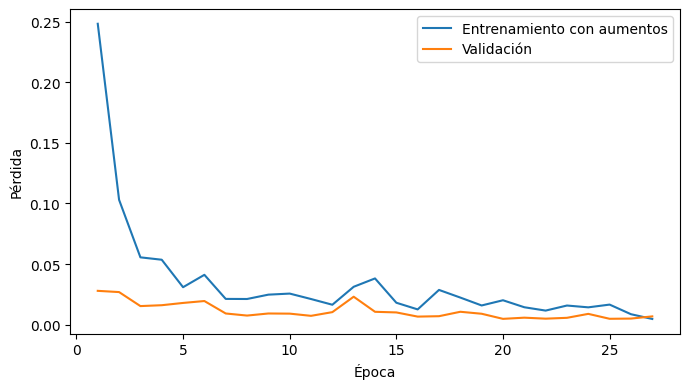

In [7]:
epocas = range(1, len(errores_entrenamiento) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epocas, errores_entrenamiento, label='Entrenamiento con aumentos')
plt.plot(epocas, errores_validacion, label='Validación')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.tight_layout()
plt.savefig(carpeta / (tarea + '_curva.png'))
plt.show()

VALIDACION
               precision    recall  f1-score   support

   Defectuosa      0.996     0.996     0.996       449
No defectuosa      0.997     0.997     0.997       735

     accuracy                          0.997      1184
    macro avg      0.996     0.996     0.996      1184
 weighted avg      0.997     0.997     0.997      1184

PRUEBA
               precision    recall  f1-score   support

   Defectuosa      0.841     0.998     0.912       449
No defectuosa      0.998     0.855     0.921       585

     accuracy                          0.917      1034
    macro avg      0.919     0.926     0.917      1034
 weighted avg      0.930     0.917     0.917      1034



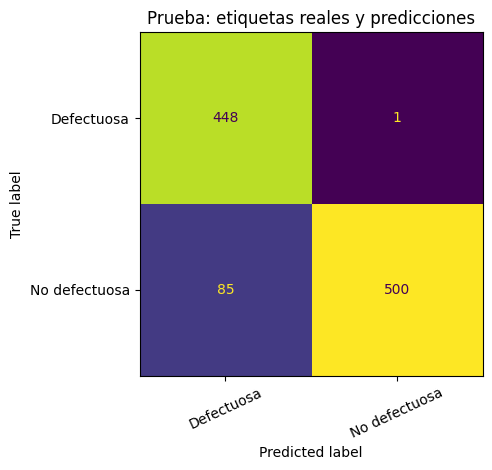

In [8]:
resultados = {}
for nombre, lotes in [('validacion', lotes_validacion), ('prueba', lotes_prueba)]:
    reales, predichas = [], []
    with torch.no_grad():
        for imagenes, etiquetas in lotes:
            salida = modelo(imagenes.to(dispositivo))
            reales.extend(etiquetas.tolist())
            predichas.extend(salida.argmax(1).cpu().tolist())
    print(nombre.upper())
    print(classification_report(reales, predichas, labels=range(len(nombres)),
                                target_names=nombres, digits=3, zero_division=0))
    resultados[nombre] = classification_report(reales, predichas, labels=range(len(nombres)),
                                              target_names=nombres, output_dict=True, zero_division=0)

ConfusionMatrixDisplay.from_predictions(reales, predichas, labels=range(len(nombres)),
                                       display_labels=nombres, xticks_rotation=25, colorbar=False)
plt.title('Prueba: etiquetas reales y predicciones')
plt.tight_layout()
plt.savefig(carpeta / (tarea + '_confusion.png'))
plt.show()

In [9]:
torch.save({'pesos': modelo.cpu().state_dict(), 'clases': nombres,
            'tamano': 128, 'media': [0.5]*3, 'desvio': [0.5]*3},
           carpeta / ('cnn_' + tarea + '.pt'))
resultados['mejor_epoca'] = mejor_epoca
resultados['perdidas'] = {'entrenamiento': errores_entrenamiento, 'validacion': errores_validacion}
with open(carpeta / (tarea + '_metricas.json'), 'w') as archivo:
    json.dump(resultados, archivo, indent=2)
print('Guardado en Drive:', 'cnn_' + tarea + '.pt')

Guardado en Drive: cnn_estado.pt


Usamos las fotos reales de [Healthy-Defective-Fruits](https://github.com/luischuquim/Healthy-Defective-Fruits). Golpes, podredumbre y manchas se agrupan como defectuosa. El CSV fija las particiones: se quitaron duplicados exactos y se agruparon imágenes muy parecidas antes de dividir. Es una evaluación exploratoria: no hay identificación de cada fruta y pueden quedar vistas relacionadas. El fondo también puede influir. Hace falta validar con otras manzanas y escenas.